<h1>
    <a href="https://github.com/CCT-Dublin/CCT_ML_CA_01_50S" target="_blank">
        <img
            src="https://cdn-icons-png.flaticon.com/128/10090/10090320.png"
            width="40"
            style="vertical-align: middle;"
        >
        GitHub Repository
    </a>
</h1>

**⚠⚠⚠Please note that if you wish to run this notebook on your own machine, you must follow all the steps provided in the [README.md](https://github.com/CCT-Dublin/CCT_ML_CA_01_50S) file. ⚠⚠⚠**

## 📢 Introduction

**🚨 Problem Definition and Motivation:**
* **Domain**: Health (Saúde)
* **Problem Type**: Supervised Machine Learning – Binary Classification
* **Target Variable ($Y$)**: Diagnosis (Malignant / Benign)

In the healthcare domain, early and accurate diagnosis of breast cancer is critical for improving patient survival rates and guiding timely medical interventions. Traditional diagnostic processes rely heavily on manual evaluation of cell nuclei characteristics, which can be time-consuming and subject to human variability.This project addresses a binary classification problem within supervised machine learning. The target variable ($Y$) is the diagnosis of a tumor, categorized as either Malignant (cancerous) or Benign (non-cancerous)8. The goal is to determine whether automated classification algorithms can reliably distinguish between malignant and benign cases based on digitized clinical features extracted from fine needle aspirate (FNA) images of breast masses.To ensure academic rigor and compliance with assessment standards, this study utilizes the real-world, publicly available Breast Cancer Wisconsin (Diagnostic) Dataset sourced from the UCI Machine Learning Repository. After cleaning, the dataset consists of **569** instances and **30** numerical features (such as radius, texture, perimeter, area, and smoothness of cell nuclei).

**🎯 Objective:**

* **Data Pre-processing and Feature Scaling:** Clean the dataset, handle categorical target encoding (`Malignant` \= 1, `Benign` \= 0), and apply standardization (`StandardScaler`) to features to optimize distance-based algorithms like kNN
* **Model Development:** Implement at least two distinct supervised classification algorithms (**[KNeighborsClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)** and **[Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)**)
* **Multi-Split Performance Evaluation:** Evaluate the variation in model accuracy across three distinct training set sizes (**5%**, **15%**, and **25%**) using **Cross-Validation** techniques to analyze how restricted training data impacts model learning and stability
* **Hyperparameter Optimization**: Apply `GridSearchCV` on one selected training data split to systematically tune key hyperparameters (e.g., shuffle, colsample_bylevel for xgboost / tree depth for Random Forest)
* **Comprehensive Metric Assessment:** Evaluate predictions using a full suite of classification metrics, including **Accuracy**, **Precision**, **Recall (Sensitivity)**, **F1-Score**, and **Confusion Matrix**. In a medical diagnostic context, particular emphasis is placed on maximizing **Recall** to minimize critical False Negatives
* **Comparative Analysis &amp; Generalization:** Interpret model outcomes, discuss trade-offs regarding **overfitting**, **underfitting**, and model generalizability.


**📈 Expected Benefits:**
* **Efficiency:** Reduce the time and cost of feedback analysis.
* **Rapid Decision-Making:** Enable medical teams to quickly identify whether the cancer is malignant or benign and decide on the best type of treatment for the patient.
* **Prioritization:** Forward the result to the medical team as a priority, improving the chances of curing or reducing the cancer.

**🤔 Information about the selected dataset**

Features are computed from a digitized image of a fine needle aspirate (FNA) of a breast mass.  They describe characteristics of the cell nuclei present in the image. A few of the images can be found at http://www.cs.wisc.edu/~street/images/

Separating plane described above was obtained using Multisurface Method-Tree (MSM-T) [K. P. Bennett, "Decision Tree Construction Via Linear Programming." Proceedings of the 4th Midwest Artificial Intelligence and Cognitive Science Society, pp. 97-101, 1992], a classification method which uses linear programming to construct a decision tree.  Relevant features were selected using an exhaustive search in the space of 1-4 features and 1-3 separating planes.

The actual linear program used to obtain the separating plane in the 3-dimensional space is that described in: [K. P. Bennett and O. L. Mangasarian: "Robust Linear Programming Discrimination of Two Linearly Inseparable Sets", Optimization Methods and Software 1, 1992, 23-34].


**📌 More details:** [Breast Cancer Wisconsin Diagnostic](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic)

## 🔄 Download the libraries if you don't have them!

In [1]:
#!pip install -r ../requirements.txt

## 🤔 JupyterLab Authoring

In [2]:
%reload_ext watermark
%watermark --author "Matheus DoS S. Silva"
%watermark --email "2026438@student.cct.ie"
%watermark --github_username "Studant --> MattheuSxS.IE | Private ~~> MattheuSxS"
%watermark --date
%watermark --python

%load_ext autoreload
%autoreload 2

Author: Matheus DoS S. Silva

Email: 2026438@student.cct.ie

Github username: Studant --> MattheuSxS.IE | Private ~~> MattheuSxS

Date: 2026-11-13

Python implementation: CPython
Python version       : 3.14.10
IPython version      : 9.18.1



## 🛂 Importing Packages

This is the workspace preparation phase. Here, we load all the necessary Python tools and libraries (such as Pandas for data manipulation, Scikit-learn for modeling, and Matplotlib/Seaborn for visualizations) that will be used throughout the project.

In [3]:
import sys
import logging
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
from typing import List, Dict
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

# ****************** Get project root directory  ****************** #
PROJECT_ROOT = Path.cwd().parent

# ***************  Add project root to Python path **************** #
sys.path.insert(0, str(PROJECT_ROOT))

In [4]:
from src.barplot import DpGraphicBar
from src.histplot import DpGraphicHist
from src.boxplot import DpGraphicBoxPlot
from src.helpful import DpGraphicHelpful

In [5]:
Bar     = DpGraphicBar()
Hist    = DpGraphicHist()
BoxPlot = DpGraphicBoxPlot()
Helpful  = DpGraphicHelpful()

In [6]:
# ***********************  Display settings *********************** #
sns.set_style('whitegrid')
%matplotlib inline

logging.basicConfig(
    format=("%(asctime)s | %(levelname)s | File_name ~> %(module)s.py "
            "| Function ~> %(funcName)s | Line ~~> %(lineno)d  ~~>  %(message)s"),
    level=logging.INFO
)

## 1️⃣ Loading and Understanding the Data

- This is the first encounter with the project's raw material. We load the data from a source (in our case, a CSV file) into a Pandas DataFrame and perform an initial check to understand its structure.

#### Auxiliary Function

The download_dataset() function is responsible for loading the dataset used in the Machine Learning project. 

- 1. It first checks whether the dataset already exists locally in the ../data directory.
- 2. If the file is not found, it attempts to download the dataset from the UC Irvine Machine Learning Repository using the fetch_ucirepo function.
- 3. If this method fails, it uses the UCI URL as a fallback.
 
Once the dataset is available, the function loads it into a Pandas DataFrame and returns it for further data analysis and Machine Learning processing. The function also includes logging and exception handling to provide information about the download and loading process.

In [7]:
def download_dataset() -> pd.DataFrame:
    data_dir = Path("../data")
    dataset_file = data_dir / "data.csv"

    data_dir.mkdir(parents=True, exist_ok=True)

    try:
        if not dataset_file.exists():

            logging.warning("📥 Dataset not found. Downloading from UC Irvine Machine Learning Repository...")

            try:
                data_dict = fetch_ucirepo(id=17) 
                df = data_dict["data"]["features"]
                df["Diagnosis"] = data_dict["data"]["targets"]

                return df

            except Exception as e:
                return pd.read_csv("https://archive.ics.uci.edu/static/public/17/data.csv", sep=",")
                
        else:
            logging.info(f"✅ Dataset already exists: {dataset_file}")

        return  pd.read_csv(dataset_file, sep=",")

    except Exception as e:
        logging.error(f"❌ Failed to download or read the dataset: {e}")

####

### 1️⃣.1️⃣. Dataset Dimensions

In [8]:
df_cancer = download_dataset()

def F_dataset_dimensions(data:pd.DataFrame) -> None:
    rows, columns = data.shape
    
    print(f"Number of rows: {rows}")
    print(f"Number of columns: {columns}")
    print(f"Dataset dimensions: {(rows, columns)}")
    print(f"Dataset size: {rows * columns:,} cells")

F_dataset_dimensions(df_cancer)

2026-11-13 17:38:12,904 | INFO | File_name ~> 1116469365.py | Function ~> download_dataset | Line ~~> 23  ~~>  ✅ Dataset already exists: ../data/data.csv


Number of rows: 569
Number of columns: 32
Dataset dimensions: (569, 32)
Dataset size: 18,208 cells


### 1️⃣.2️⃣. Dataset Information

In [9]:
df_cancer.head()

,ID,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
0,842302,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,842517,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,84300903,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,84348301,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,84358402,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


In [10]:
df_cancer.tail(5)

,ID,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
564,926424,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,M
565,926682,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,M
566,926954,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,M
567,927241,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,M
568,92751,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,B


In [11]:
df_cancer.sample(3)

,ID,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
485,913063,12.45,16.41,82.85,476.7,0.09514,0.1511,0.1544,0.04846,0.2082,...,21.03,97.82,580.6,0.1175,0.4061,0.4896,0.1342,0.3231,0.10340,B
218,8811842,19.80,21.56,129.70,1230.0,0.09383,0.1306,0.1272,0.08691,0.2094,...,28.64,170.30,2009.0,0.1353,0.3235,0.3617,0.1820,0.3070,0.08255,M
6,844359,18.25,19.98,119.60,1040.0,0.09463,0.1090,0.1127,0.07400,0.1794,...,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368,M


In [12]:
print(f"Dataset columns: \n\n{list(df_cancer.columns)}")

Dataset columns: 

['ID', 'radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3', 'Diagnosis']


In [13]:
df_cancer.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  569 non-null    int64  
 1   radius1             569 non-null    float64
 2   texture1            569 non-null    float64
 3   perimeter1          569 non-null    float64
 4   area1               569 non-null    float64
 5   smoothness1         569 non-null    float64
 6   compactness1        569 non-null    float64
 7   concavity1          569 non-null    float64
 8   concave_points1     569 non-null    float64
 9   symmetry1           569 non-null    float64
 10  fractal_dimension1  569 non-null    float64
 11  radius2             569 non-null    float64
 12  texture2            569 non-null    float64
 13  perimeter2          569 non-null    float64
 14  area2               569 non-null    float64
 15  smoothness2         569 non-null    float64
 16  compactness2       

### 1️⃣.3️⃣. Data Types Distribution

- A visualization to identify the number of attributes by data type.

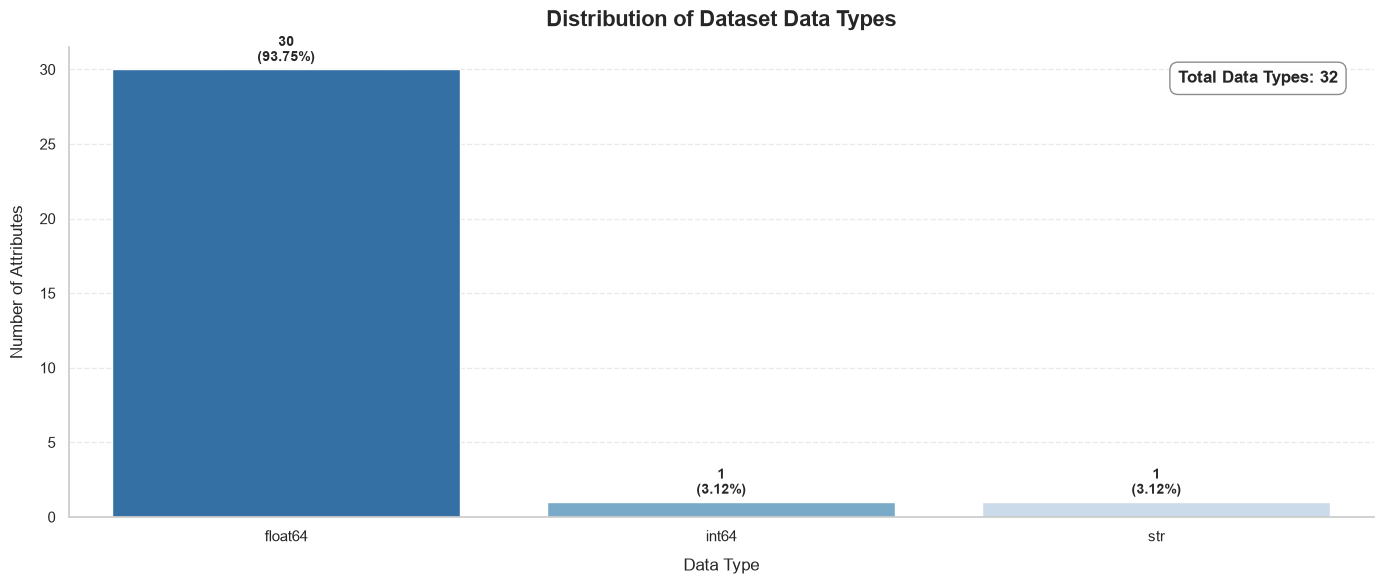

In [14]:
Bar.F_datatypes_barplot(data=df_cancer)

### 1️⃣.4️⃣. Missing Values Analysis

- Displaying only the columns with missing values and showing their respective percentages

⚠⚠⚠ Missing values can affect data quality and influence the reliability of subsequent statistical analyses. Therefore, identifying their distribution across the dataset is an important part of the initial data assessment. ⚠⚠⚠

In [15]:
Bar.F_missing_barplot(df_cancer)

2026-11-13 17:38:13,103 | WARNING | File_name ~> barplot.py | Function ~> F_missing_barplot | Line ~~> 95  ~~>  No missing values found.


### 1️⃣.5️⃣. Duplicate Records

- Checking how many null rows we have and what the percentage of that is
  
⚠⚠⚠ Duplicate records may introduce redundancy and affect the reliability of statistical analysis. The dataset is therefore examined to identify completely duplicated observations. ⚠⚠⚠

In [16]:
duplicate_count = df_cancer.duplicated().sum()
duplicate_percentage = (duplicate_count / len(df_cancer)) * 100

print(f"Duplicate records ~~> {duplicate_count:,}")
print(f"Duplicate percentage ~~> {duplicate_percentage:.2f}%")

Duplicate records ~~> 0
Duplicate percentage ~~> 0.00%


## 2️⃣ Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to better understand [Breast Cancer Wisconsin Diagnostic](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic) dataset and identify patterns, distributions, and relationships between its variables.

**👨🏾‍🏫 What you will find in this stage:**

- Descriptive statistics,
- Target variable analysis,
- Numerical feature distributions
- Correlation analysis. 

These investigations provide an initial understanding of the data and support the subsequent data preparation and feature selection stages.

### 2️⃣.1️⃣. Descriptive Statistics

In [17]:
numerical_features = [
    column
    for column in df_cancer.keys()
        if df_cancer[column].dtypes == "float64"
    ]

In [18]:
df_cancer[numerical_features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
radius1,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
texture1,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
perimeter1,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
area1,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
smoothness1,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
compactness1,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
concavity1,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
concave_points1,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
symmetry1,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
fractal_dimension1,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


### 2️⃣.2️⃣. Target Variable Analysis

The target variable, Diagnosis, indicates whether a breast tumor have been classified as benign or malignant. Analyzing its distribution helps us understand the proportion of observations belonging to each diagnostic category.

The dataset contains two classes:

- B (Benign) ~~> `357` observations `(62.74%)`.
- M (Malignant) ~~> `212` observations `(37.26%)`.

The distribution shows that benign cases represent the majority of observations, while malignant cases account for a smaller proportion. This difference is relevant when evaluating the classification models, as the distribution of target classes should be considered when interpreting their performance.

**⚠⚠⚠However, we can already see class imbalance in this variable, which will be addressed later on.⚠⚠⚠**

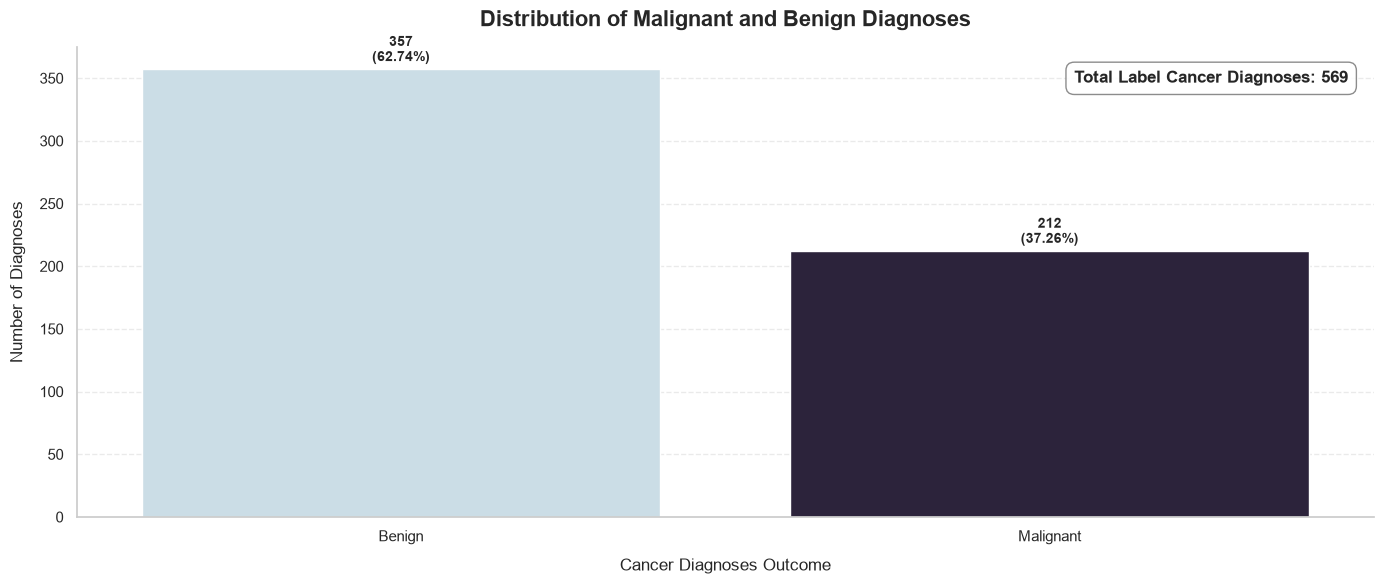

In [19]:
target_labels = ["M", "B"]
target_names = ["Malignant", "Benign"]

Bar.F_target_barplot(df_cancer, 'Diagnosis', target_labels, target_names)

### 2️⃣.3️⃣. Numerical Feature Distribution

#### 2️⃣.3️⃣.1️⃣. Histogram — Distribution Analysis

**🤔 What you will find:**
- Frequency and concentration of values.
- Shape of the distributions.
- Possible asymmetries (skewness).
- Differences in the behavior of numerical variables.

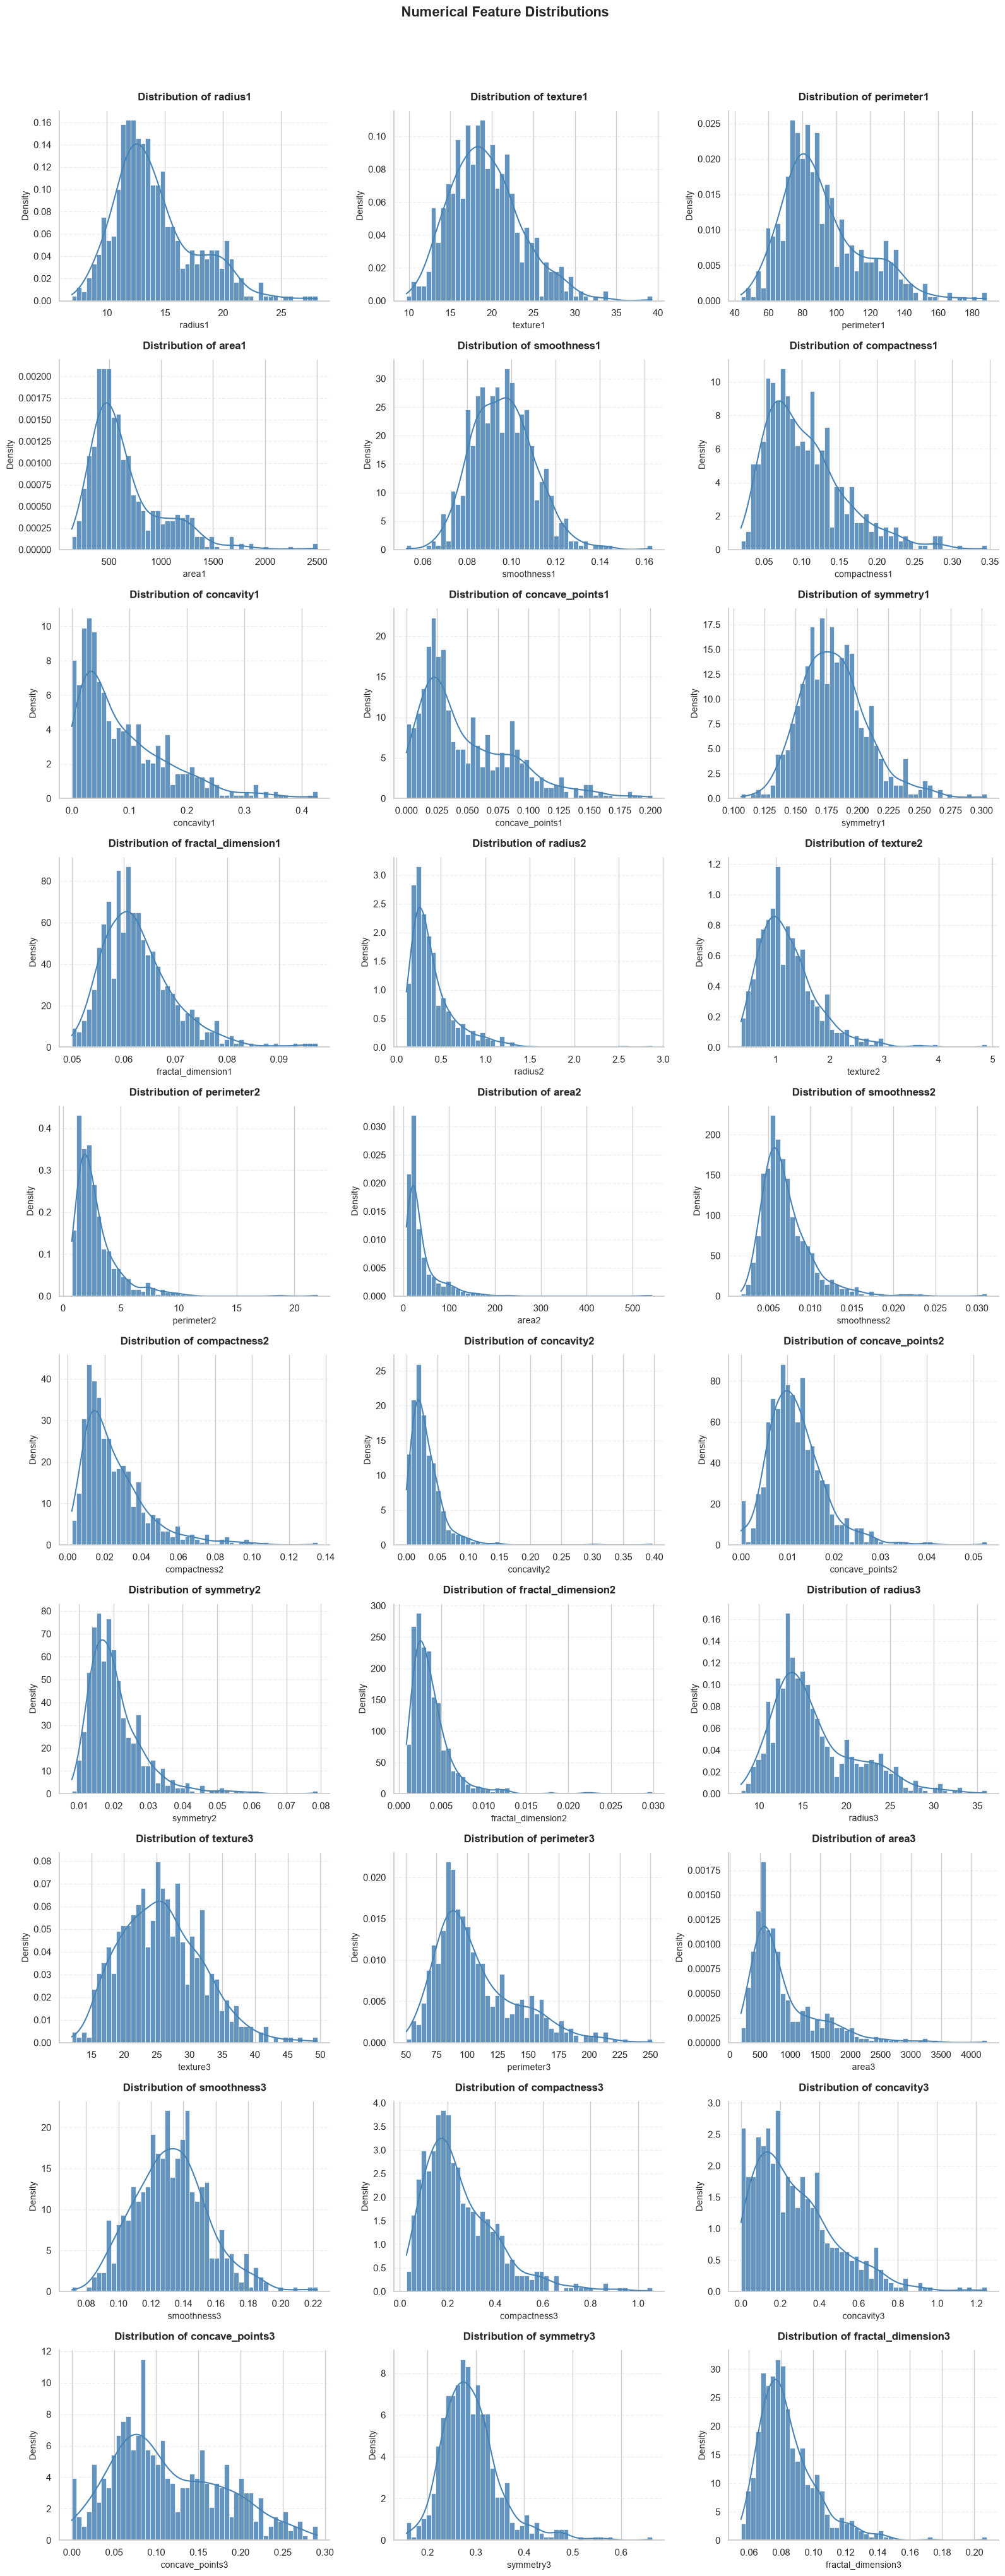

In [20]:
Hist.F_histplot(df_cancer, numerical_features)

#### 2️⃣.3️⃣.2️⃣. Boxplot — Outlier Analysis

**🤔 What you will find:**
- Median.
- First and third quartiles (Q1 and Q3).
- Interquartile range (IQR).
- Lower and upper whiskers.
- Potential outliers.

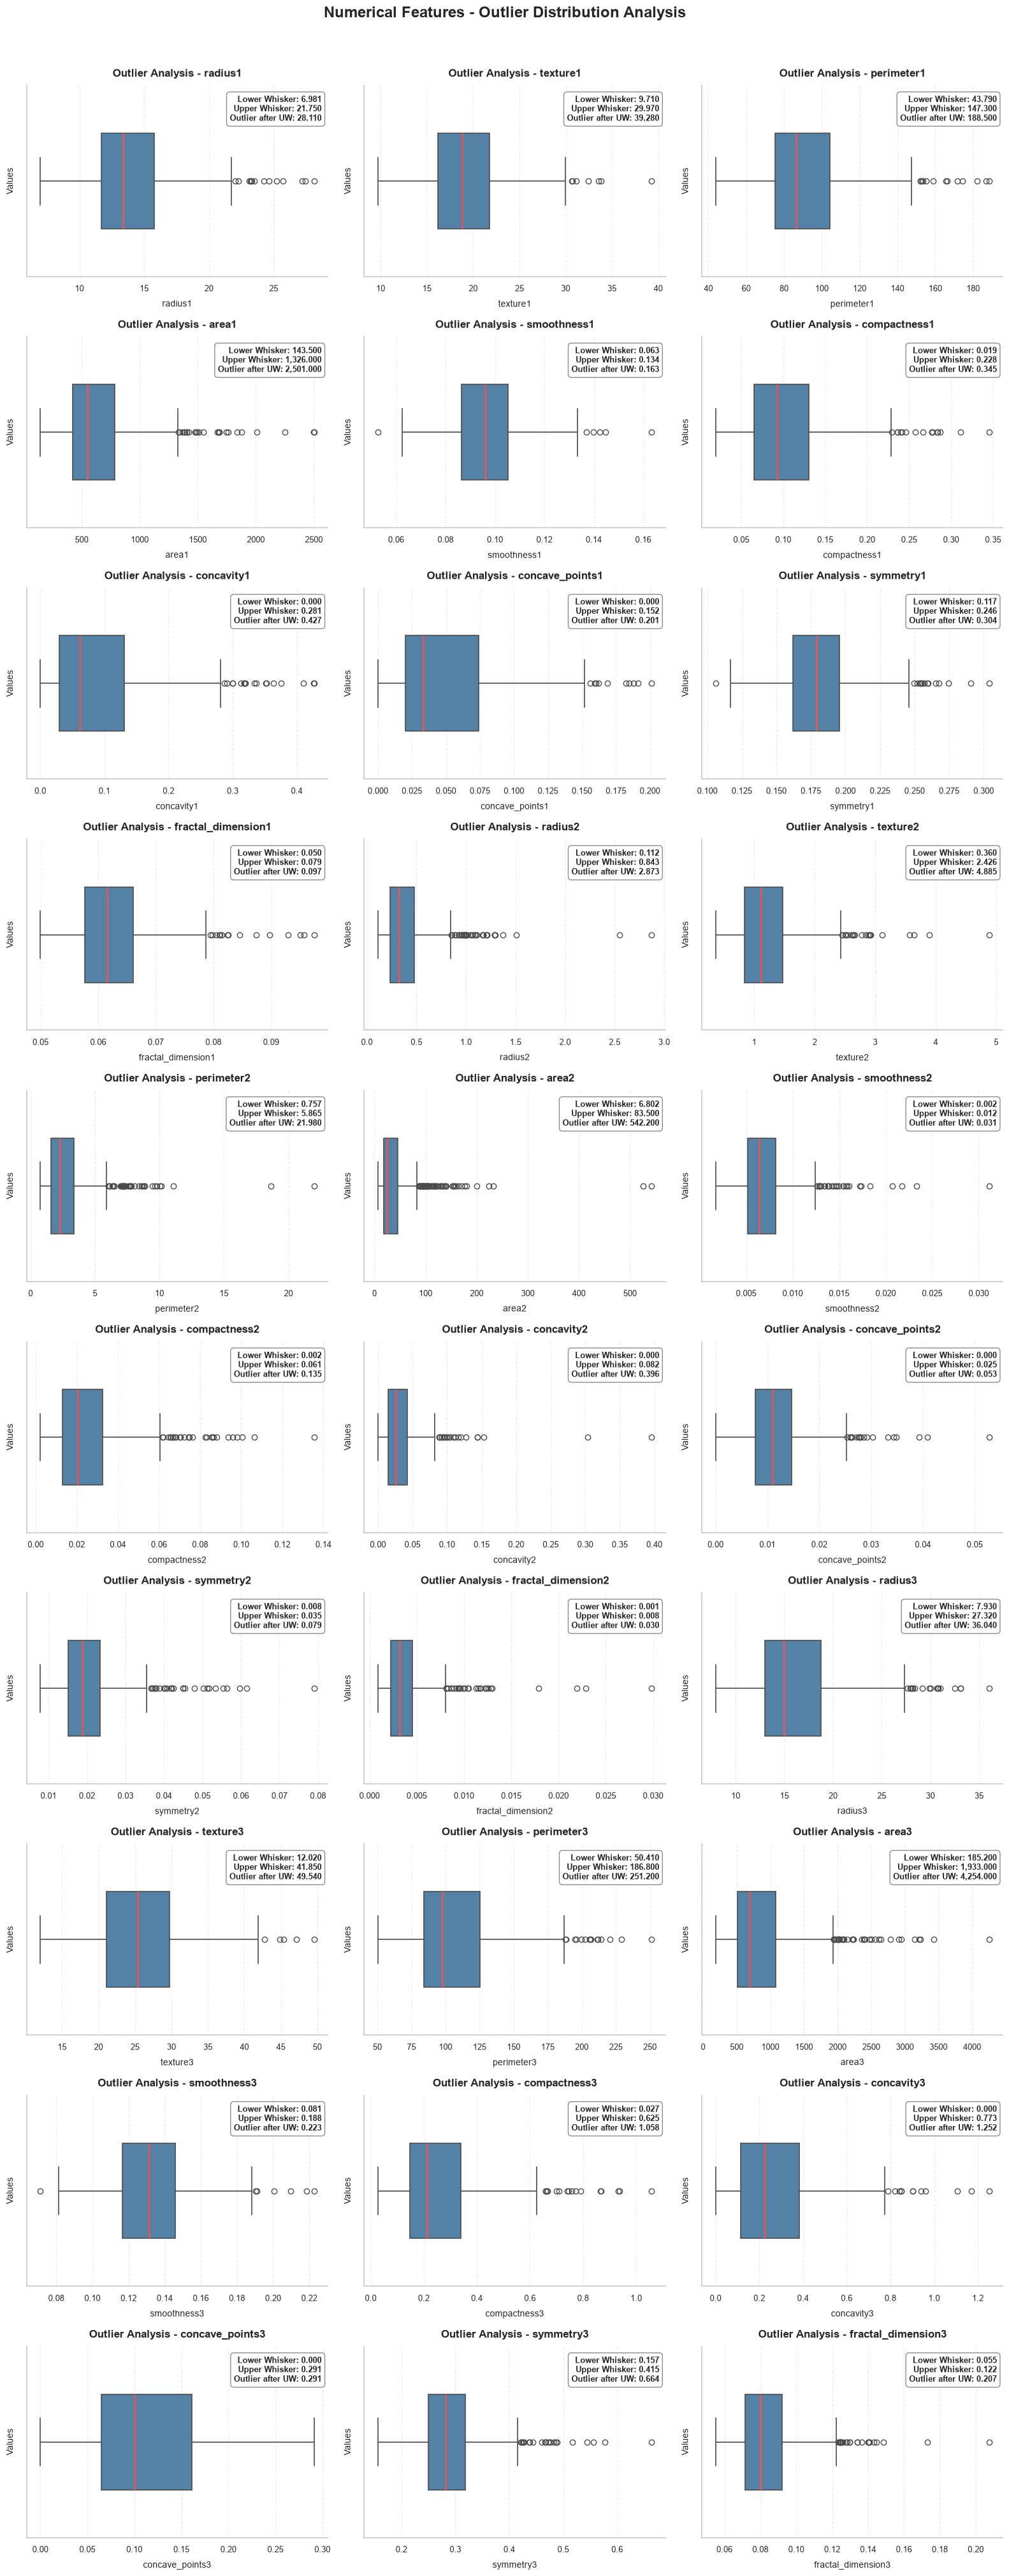

In [21]:
BoxPlot.F_boxplot_v1(df_cancer, numerical_features)

### 2️⃣.4️⃣. Feature Relationships and Correlation

#### 2️⃣.4️⃣.1️⃣. Correlation Matrix

**🤔 What you will find**
- **Positive correlation ~~>** two variables tend to increase together.
- **Negative correlation ~~>** when one variable increases, the other tends to decrease.
- **Weak correlation     ~~>** little linear relationship between the variables.
- **Strong correlation   ~~>** a more intense linear relationship between the variables.


**🚨 Correlation, by itself, does not measure the predictive importance of a variable; variable selection will be addressed in section `4️⃣ Feature Selection` 🚨**.

<a id="correlation_matrix"></a>

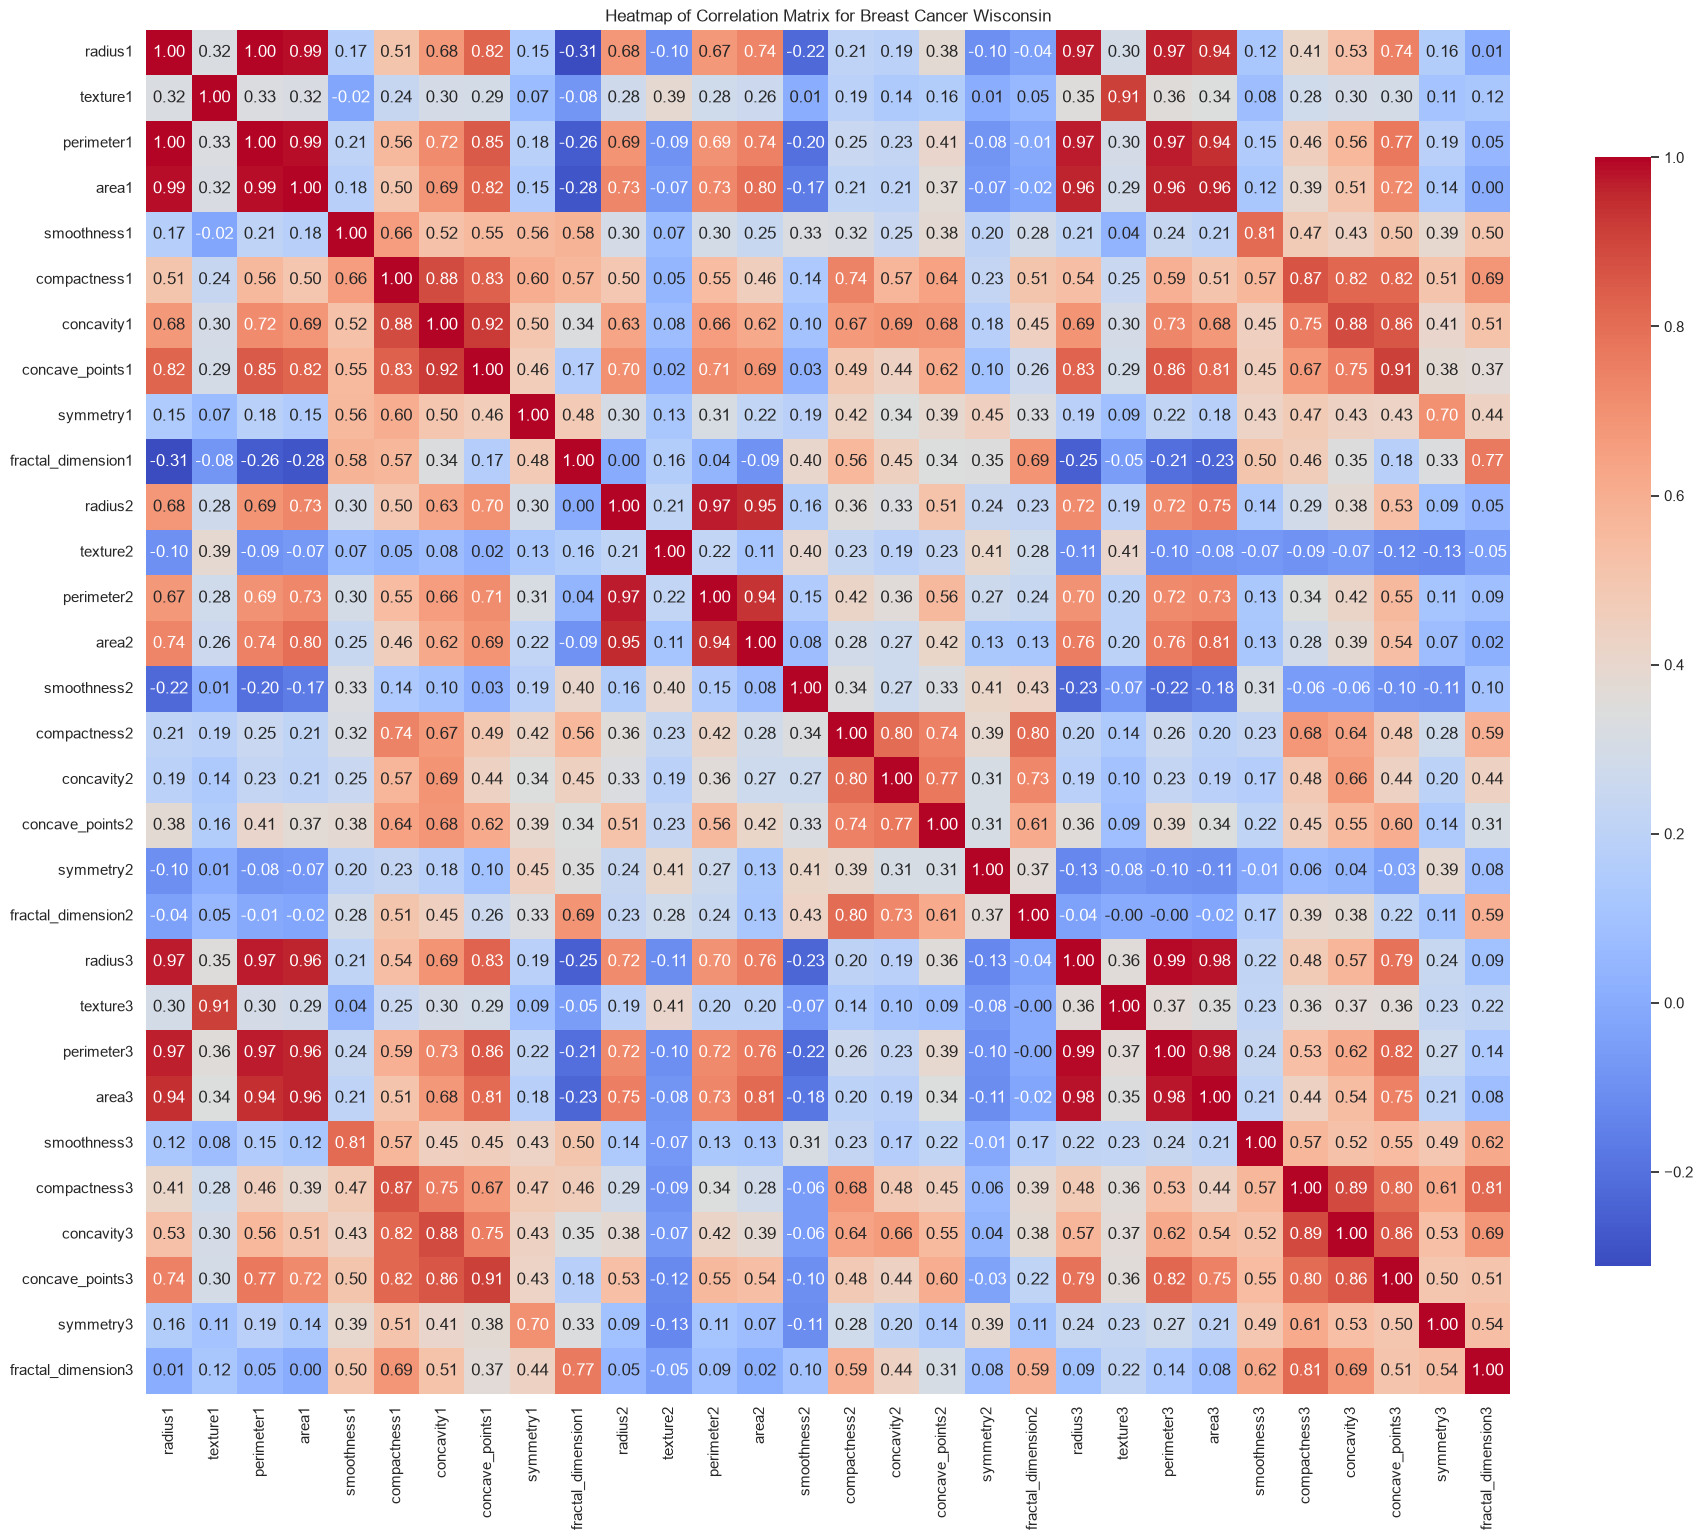

In [22]:
Helpful.F_correlation_matrix(df_cancer.drop(columns="ID"), numerical_features, 2)

## 3️⃣ Data Cleaning and Transformation

👨🏾‍🏫 What you will find in this stage:

- Removing irrelevant information
- Transforming the target variable
- Applying the necessary preprocessing techniques
- Assessing class distribution
- Validating the dataset to ensure its consistency
- Suitability for the classification models.


### 3️⃣.1️⃣. Irrelevant Feature Removal

The `ID` column has been removed because it represents a unique identifier for each observation, in other words, remove this feature helps ensure that the classification models are trained using relevant information.

In [23]:
try:
    df_clean = df_cancer.drop(columns="ID")
    logging.info(f"The ID column has been successfully removed.")
except KeyError as e:
    logging.warning(f" The ID column has not been in dataset")

2026-11-13 17:38:17,110 | INFO | File_name ~> 3071977550.py | Function ~> <module> | Line ~~> 3  ~~>  The ID column has been successfully removed.


### 3️⃣.2️⃣ Target Variable Encoding

The target `Diagnosis`, contains two categorical classes:
- Benign (B) = 0
- Malignant (M) = 1

Label Encoding has been applied to convert these categories into numerical values.

In [24]:
from sklearn import preprocessing

In [25]:
label_encoder = preprocessing.LabelEncoder()

df_clean['Diagnosis'] = label_encoder.fit_transform(df_clean['Diagnosis']) 

### 3️⃣.3️⃣ Data StandardScaler

Feature standardization will be applied to ensure that numerical variables have a consistent scale. This transformation is particularly important for distance-based algorithms such as K-Nearest Neighbors (KNN) that we are going to use later on, where differences in feature scales can influence distance calculations.

In [26]:
def F_StandardScaler(data:pd.DataFrame):
    from sklearn.preprocessing import StandardScaler
    
    return StandardScaler().fit(data)

### 3️⃣.4️⃣ Class Imbalance Assessment

The target variable distribution is evaluated to identify potential class imbalance betwen Benign and Malignant diagnoses. Model performance is initially assessed using the original class distribution. If the results showing that class imbalance negative affects classification performance, resampling techniques such as SMOTE may be considered.

In [27]:
def F_SMOTE(X_train:pd.DataFrame, y_train:pd.DataFrame) -> tuple:
    from imblearn.over_sampling import SMOTE

    smote = SMOTE(random_state=42)

    return smote.fit_resample(X_train, y_train)

### 3️⃣.5️⃣. Data Quality Validation

⚠⚠⚠ In this stage, we will verify the consistency and integrity of the prepared dataset. This includes checking the expected columns, data types, missing values, number of observations, and valid target variable values to ensure that the dataset is ready for the subsequent machine learning stages.. ⚠⚠⚠

In [28]:
expected_columns = \
    [
        'radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1',
        'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2',
        'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3',
        'concave_points3', 'symmetry3', 'fractal_dimension3', 'Diagnosis'
    ]

In [29]:
assert set(expected_columns).issubset(df_clean.columns), \
    f"Missing columns: {set(expected_columns) - set(df_cancer.columns)}"

In [30]:
assert set(df_clean.columns) == set(expected_columns), \
    f"Column mismatch. Missing: {set(expected_columns) - set(df_clean.columns)} | Unexpected: {set(df_clean.columns) - set(expected_columns)}"

In [31]:
for column in expected_columns:
    assert df_clean[column].isnull().sum() == 0, \
        f"Missing values still exist in the dataset at {column} column!"

In [32]:
for column in expected_columns:
    match column:
        case "ID" | "Diagnosis":
            assert str(df_clean[column].dtype) == "int64", (
                f"Invalid dtype in column: {column} | Expected: int64 | Found: {df_clean[column].dtype}")
        case _:
            assert str(df_clean[column].dtype) == "float64", (
                f"Invalid dtype in column: {column} | Expected: float64 | Found: {df_clean[column].dtype}")

In [33]:
assert len(df_clean[numerical_features]) == 569, \
    "The number of records the numerical features is not correct"

In [34]:
assert len(df_clean["Diagnosis"]) == 569, \
    "The number of records after label encoder"

In [35]:
assert set(df_clean["Diagnosis"].unique()) == {0, 1}, \
    "Invalid values found in Diagnosis!"

## 4️⃣ Feature Selection

The idea behind feature selection is to work out which variables are most relevant for the classification task and to cut down on including features that are redundant or less informative.

This stage uses three different approaches:
- Correlation analysis
- Statistical feature selection using SelectKBest
- Model-based feature importance using Random Forest.

We will compare the top 15 features from each method to spot any common variables and see how consistent the selection results are. This process helps to set up a suitable set of predictors for the subsequent machine learning models.

 ### 4️⃣.1️⃣. Correlation Analysis

Correlation analysis is a way of looking at the links between numerical features and finding out what variables may contain similar or repeated information. The correlation matrix shows these relationships and helps identify important features for the classification task.

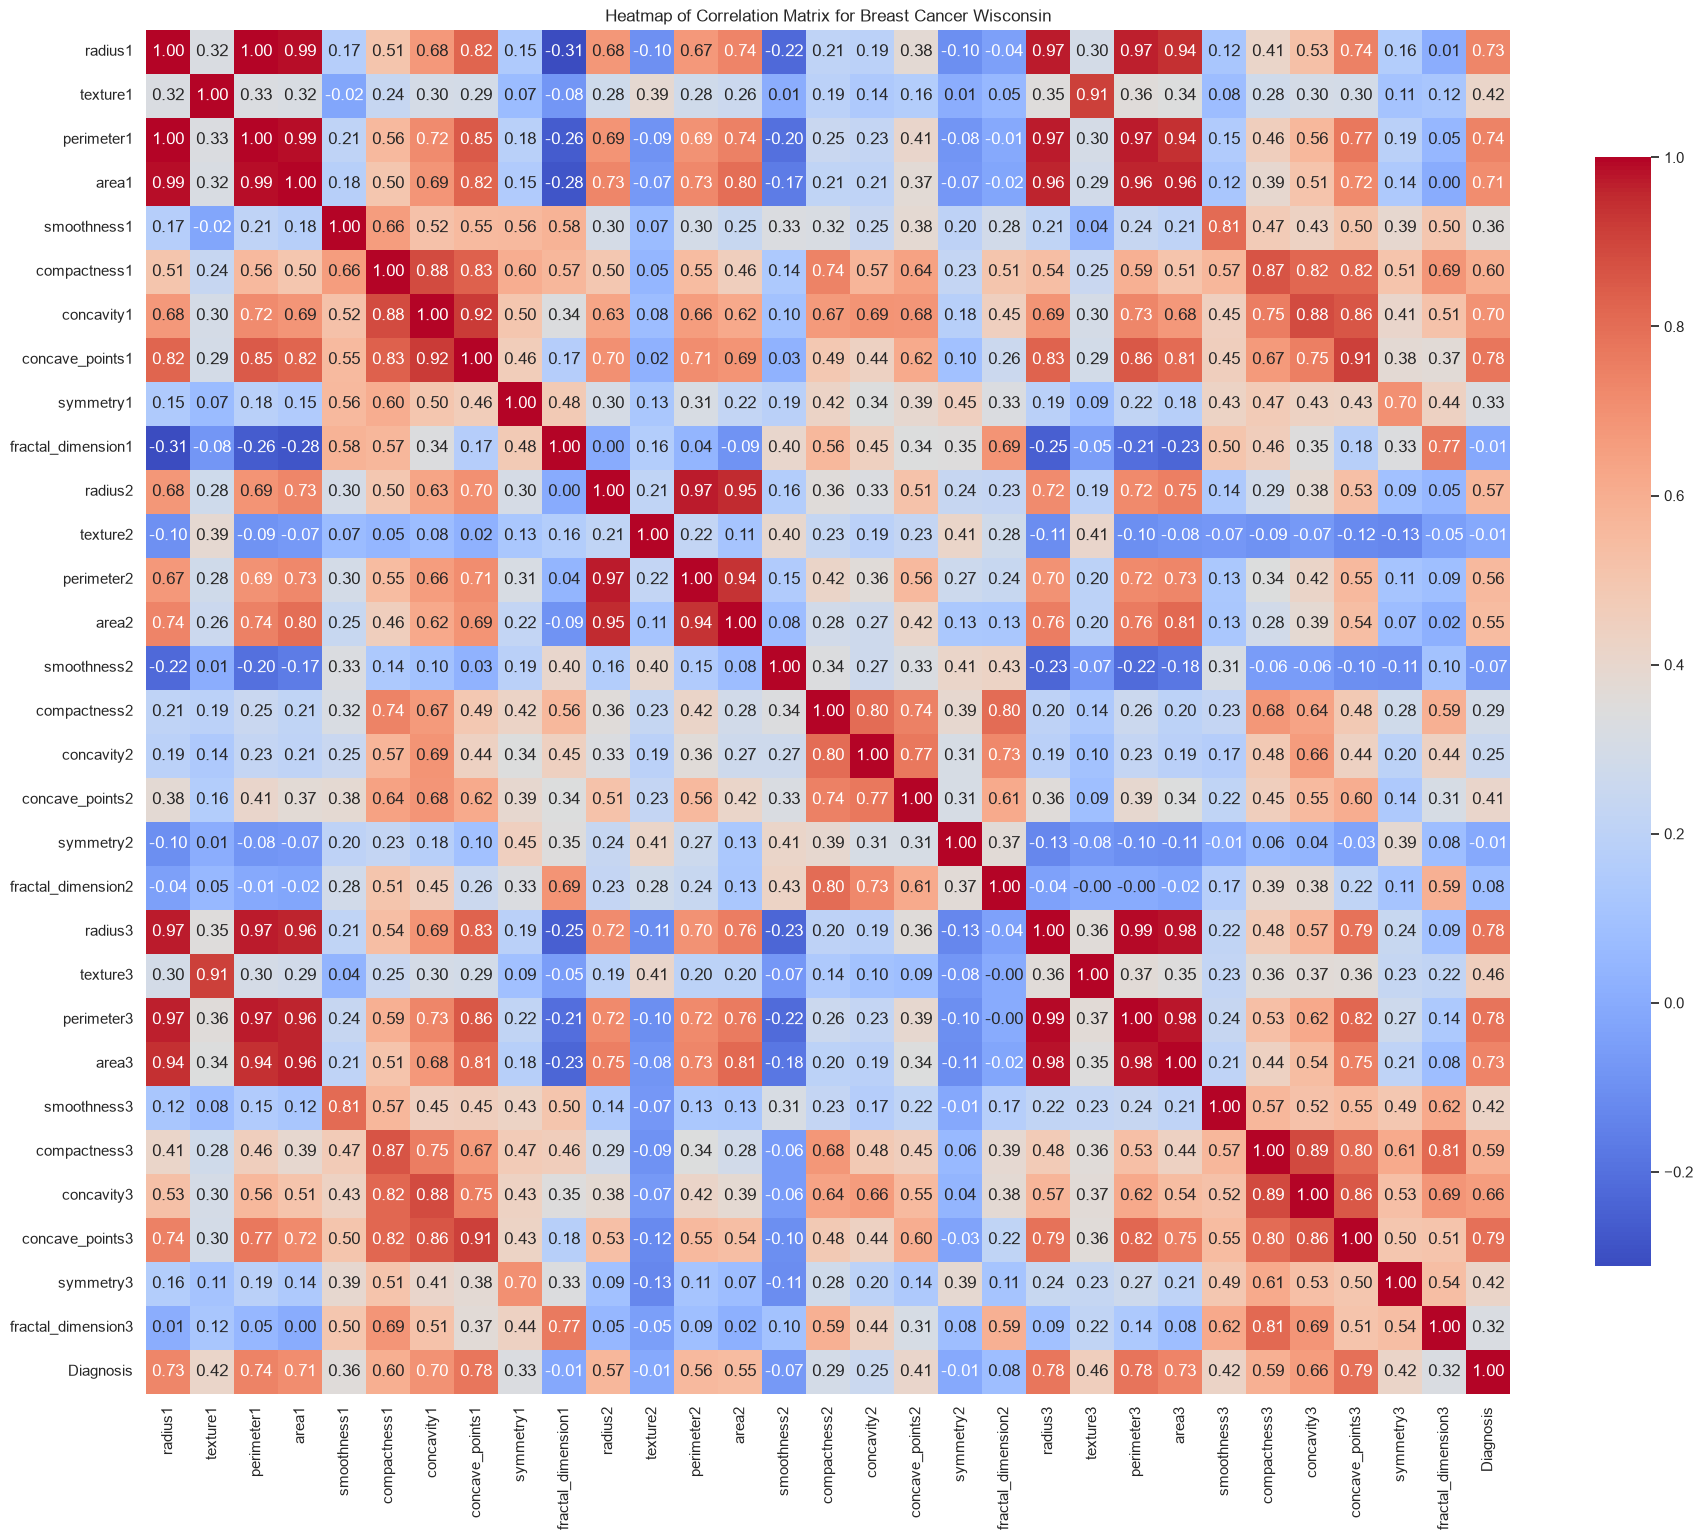

In [36]:
Helpful.F_correlation_matrix(df_clean, numerical_features, 2)

In [37]:
correlation = df_clean.corr()['Diagnosis'].drop('Diagnosis')

features_corr_15 = correlation.abs().nlargest(15).index.tolist()
features_corr_15

['concave_points3',
 'perimeter3',
 'concave_points1',
 'radius3',
 'perimeter1',
 'area3',
 'radius1',
 'area1',
 'concavity1',
 'concavity3',
 'compactness1',
 'compactness3',
 'radius2',
 'perimeter2',
 'area2']

### 4️⃣.2️⃣. Statistical Feature Selection

The SelectKBest method with the f_classif scoring function is used to select the statistical features. This approach looks at the statistical relationship between each feature and the target variable, and picks the 15 features with the highest scores.

In [38]:
from sklearn.feature_selection import SelectKBest, f_classif

In [39]:
X = df_clean.drop(columns="Diagnosis")
y = df_clean["Diagnosis"]

better_k = 15
selector = SelectKBest(score_func=f_classif, k=better_k)
X_new = selector.fit_transform(X, y)

df_skbest = pd.DataFrame({
    'Feature': numerical_features,
    'F-Score': selector.scores_,
    'P-Value': selector.pvalues_,
    'Selecionada': selector.get_support()
}).sort_values(by='F-Score', ascending=False).reset_index(drop=True)

features_skbest_15 = df_skbest['Feature'].head(15).tolist()

features_skbest_15

['concave_points3',
 'perimeter3',
 'concave_points1',
 'radius3',
 'perimeter1',
 'area3',
 'radius1',
 'area1',
 'concavity1',
 'concavity3',
 'compactness1',
 'compactness3',
 'radius2',
 'perimeter2',
 'area2']

### 4️⃣.3️⃣. Model-Based Feature Importance

Model-based feature selection uses a Random Forest classifier to estimate how important each feature is. The features are given a rank based on how important they are, which helps to identify the 15 variables that have the most impact on the model's predictions.

In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel

In [41]:
X = df_clean.drop(columns="Diagnosis")
y = df_clean["Diagnosis"]

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X, y)

df_rf_analise = pd.DataFrame({
    'Feature': X.columns,
    'Importancia_RF': rf_model.feature_importances_
}).sort_values(by='Importancia_RF', ascending=False).reset_index(drop=True)

features_rf_15 = df_rf_analise['Feature'].head(15).tolist()

features_rf_15

['area3',
 'concave_points3',
 'concave_points1',
 'radius3',
 'perimeter3',
 'perimeter1',
 'concavity1',
 'area1',
 'concavity3',
 'radius1',
 'area2',
 'compactness3',
 'texture3',
 'texture1',
 'radius2']

### 4️⃣.4️⃣ Feature Selection Assessment

We're comparing the results from the three feature selection approaches to see what features are the same and what's different in their rankings. This helps us see how consistent the methods are and helps us decide which features to think about in the next modelling stage.

In [42]:
pd.DataFrame({
    "Correlation": features_corr_15,
    "SelectKBest": features_skbest_15,
    "Random_Forest": features_rf_15
})

,Correlation,SelectKBest,Random_Forest
0,concave_points3,concave_points3,area3
1,perimeter3,perimeter3,concave_points3
2,concave_points1,concave_points1,concave_points1
3,radius3,radius3,radius3
4,perimeter1,perimeter1,perimeter3
5,area3,area3,perimeter1
6,radius1,radius1,concavity1
7,area1,area1,area1
8,concavity1,concavity1,concavity3
9,concavity3,concavity3,radius1


In [43]:
match_features = list(set(features_corr_15).intersection(
    set(features_skbest_15), 
    set(features_rf_15)
))

print(f"📊 Number of features common to all 3 methods: {len(match_features)} of 15\n")
print("✨ Features that appear in ALL THREE rankings:")
for f in sorted(match_features):
    print(f"  - {f}")

📊 Number of features common to all 3 methods: 13 of 15

✨ Features that appear in ALL THREE rankings:
  - area1
  - area2
  - area3
  - compactness3
  - concave_points1
  - concave_points3
  - concavity1
  - concavity3
  - perimeter1
  - perimeter3
  - radius1
  - radius2
  - radius3


##### Result 🕵🏾


1... Correlation vs. SelectKBest (Complete Convergence)

- The Correlation and selectKBest methods produced absolutely identical results regarding the 15 selected features and their ranking order.
- This occurs because, mathematically, for a binary target variable (such as Diagnosis), the ANOVA statistical test (f_classif) and the linear correlation coefficient have a direct mathematical equivalence.

2... Random Forest (Multivariate Perspective)

- The random_Forest method slightly changed the ranking order (placing area3 at the top, for example) and replaced two features compared to the other two methods.
- This happens because decision trees evaluate feature importance by considering non-linear interactions and the combined information gain, rather than assessing each feature individually.

3... Absolute Consensus

- In other words, 13 out of the 15 features (86.6%) are exactly the same across all three methods.
- This demonstrates that these 13 features have extremely strong and consistent predictive power for the diagnosis, regardless of the statistical algorithm used.

## 5️⃣ Training and Test Splitting

An essential step for model training and evaluation. We split the dataset into two parts: a larger one (training), which the model uses to learn, and a smaller one (test), which is kept "hidden" from the model to simulate new data and evaluate its actual performance after training.

**As stated in the document, the data needs to be split into the following formats [ 5%, 15%, and 25% ], so we will use a function to avoid code duplication.**

In [44]:
def F_splittint_data(data:pd.DataFrame, label:pd.DataFrame, _test_size:float = 0.30, _random_state:int = 25):
    from sklearn.model_selection import train_test_split
    
    _test  = (_test_size * 100)
    _train = 100 - _test
    logging.info(f"The data has splitted in {_train}% to train and {_test}% to test...")

    return train_test_split(data, label, test_size = _test_size, random_state = _random_state, stratify=label)

## 6️⃣. Predictive Modeling Pipeline

Here, we build an automated production pipeline for our model. The Scikit-learn Pipeline encapsulates all preprocessing stepS and the final model (Supervised Classification Models), ensuring that the same steps are consistently applied to both the training data and new data.


**Initially, we will use the three models below.**

* [Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)
* [KNeighborsClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)

### 6️⃣.1️⃣ Building Random Forest Model

In [45]:
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier

target_labels = [0, 1]
target_names = ["Benign", "Malignant",]

In [46]:
def get_clean_data() -> pd.DataFrame:
    X = df_clean[match_features].copy()
    y = df_clean["Diagnosis"].copy()

    return X, y

In [47]:
X, y = get_clean_data()

X_train, X_test, y_train, y_test = F_splittint_data(X, y)

clf = RandomForestClassifier(n_estimators=500,random_state=42)
clf.fit(X_train, y_train)

rf_result = clf.predict(X_test)

2026-11-13 17:38:18,610 | INFO | File_name ~> 949381992.py | Function ~> F_splittint_data | Line ~~> 6  ~~>  The data has splitted in 70.0% to train and 30.0% to test...


In [48]:
print("*****************************************************")
print("*************** Random Forest Predict ***************")
print("*****************************************************\n")
print(
    classification_report(
        y_true       = y_test,
        y_pred       = rf_result,
        target_names = target_names,
        digits       = 4
    )
)

*****************************************************
*************** Random Forest Predict ***************
*****************************************************

              precision    recall  f1-score   support

      Benign     0.9537    0.9626    0.9581       107
   Malignant     0.9365    0.9219    0.9291        64

    accuracy                         0.9474       171
   macro avg     0.9451    0.9422    0.9436       171
weighted avg     0.9473    0.9474    0.9473       171



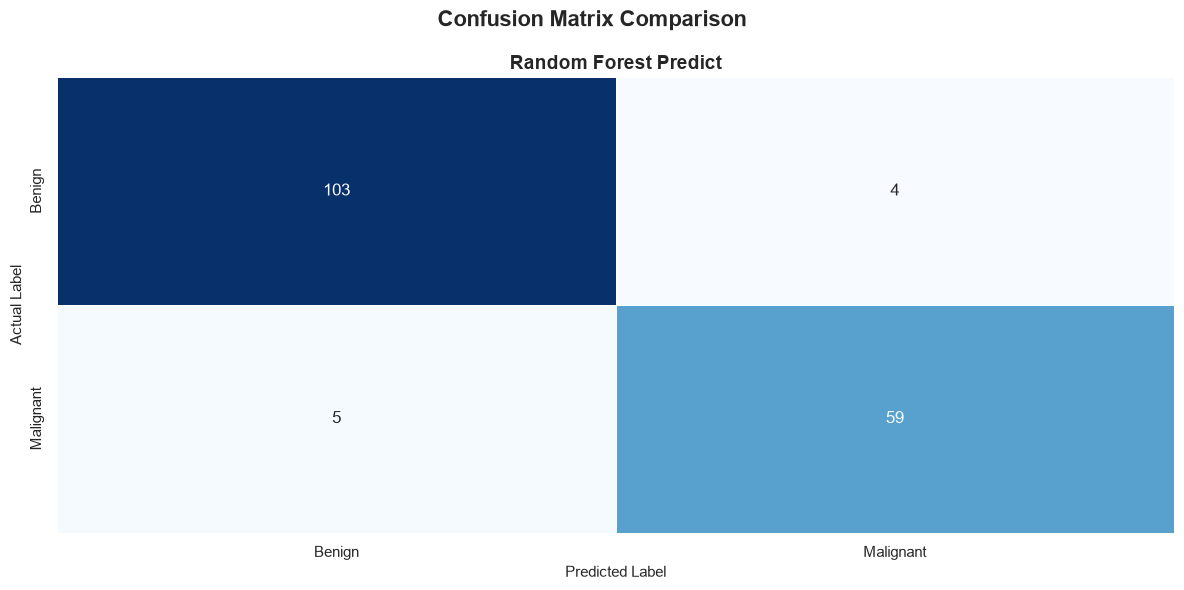

In [49]:
Helpful.F_confusion_matrix(
    y_true=y_test,
    y_pred_1=rf_result,
    title_1="Random Forest Predict",
    labels=target_labels,
    class_names=target_names
)

### 6️⃣.2️⃣ Building KNeighborsClassifier Model

In [50]:
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

In [51]:
X, y = get_clean_data()

X_train, X_test, y_train, y_test = F_splittint_data(X, y)

2026-11-13 17:38:18,970 | INFO | File_name ~> 949381992.py | Function ~> F_splittint_data | Line ~~> 6  ~~>  The data has splitted in 70.0% to train and 30.0% to test...


In [52]:
F_Scaler = F_StandardScaler(X_train)

X_train = F_Scaler.transform(X_train)
X_test = F_Scaler.transform(X_test)

In [53]:
kNN = KNeighborsClassifier(n_neighbors = 5)

kNN.fit(X_train, y_train)
knn_result = kNN.predict(X_test)

In [54]:
print("*****************************************************")
print("*************** Random Forest Predict ***************")
print("*****************************************************\n")
print(
    classification_report(
        y_true       = y_test,
        y_pred       = knn_result,
        target_names = target_names,
        digits       = 4
    )
)

*****************************************************
*************** Random Forest Predict ***************
*****************************************************

              precision    recall  f1-score   support

      Benign     0.9626    0.9626    0.9626       107
   Malignant     0.9375    0.9375    0.9375        64

    accuracy                         0.9532       171
   macro avg     0.9501    0.9501    0.9501       171
weighted avg     0.9532    0.9532    0.9532       171



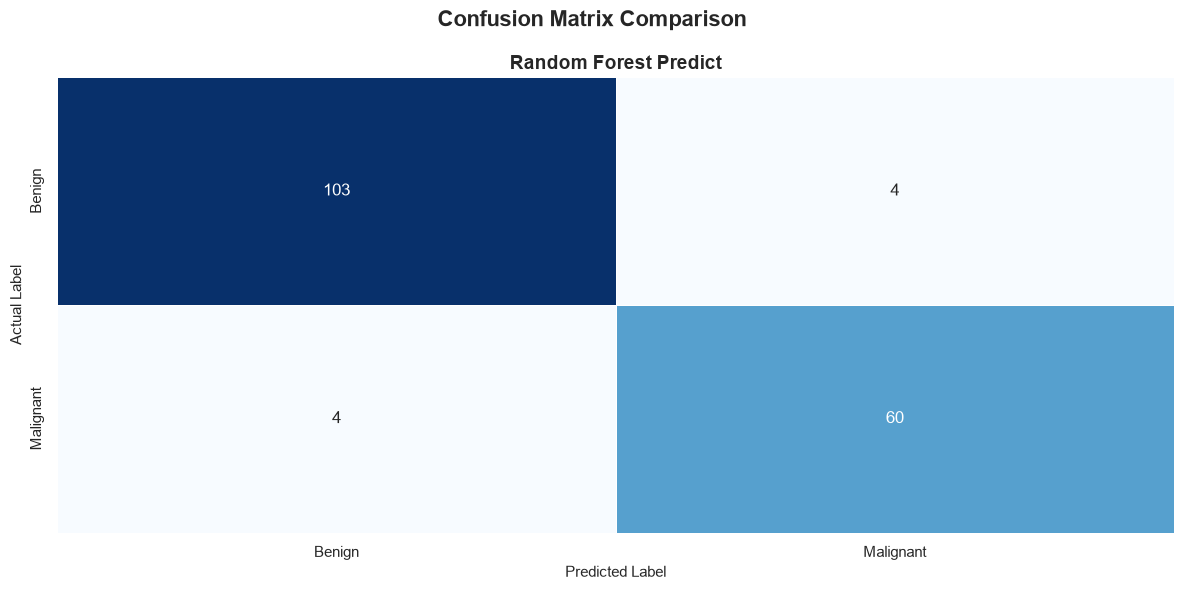

In [55]:
Helpful.F_confusion_matrix(
    y_true=y_test,
    y_pred_1=knn_result,
    title_1="Random Forest Predict",
    labels=target_labels,
    class_names=target_names
)

## 7️⃣. Cross-Validation

In [56]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

test_sizes = [0.05, 0.15, 0.25]

### 7️⃣.1️⃣. Cross Validation ~~> Random Forest Classifier

In [57]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf_results = []

for test_size in test_sizes:

    X_train, X_test, y_train, y_test = X_train, X_test, y_train, y_test = F_splittint_data(X, y, test_size)

    rf_model = RandomForestClassifier(n_estimators=500, random_state=42)

    cv_scores = cross_val_score(
        estimator = rf_model,
        X         = X_train,
        y         = y_train,
        cv        = cv,
        scoring   = "accuracy")

    rf_model.fit(X_train, y_train)
    y_pred = rf_model.predict(X_test)

    test_accuracy = accuracy_score(y_test, y_pred)

    rf_results.append({
        "Model": "Random Forest",
        "Test Size": f"{test_size:.0%}",
        "Training Size": f"{1 - test_size:.0%}",
        "Fold 1": cv_scores[0],
        "Fold 2": cv_scores[1],
        "Fold 3": cv_scores[2],
        "Fold 4": cv_scores[3],
        "Fold 5": cv_scores[4],
        "CV Mean": np.mean(cv_scores),
        "CV Std": np.std(cv_scores),
        "Test Accuracy": test_accuracy
    })

    del X_train, X_test, y_train, y_test 

df_rf_results = pd.DataFrame(rf_results)

2026-11-13 17:38:19,102 | INFO | File_name ~> 949381992.py | Function ~> F_splittint_data | Line ~~> 6  ~~>  The data has splitted in 95.0% to train and 5.0% to test...
2026-11-13 17:38:20,742 | INFO | File_name ~> 949381992.py | Function ~> F_splittint_data | Line ~~> 6  ~~>  The data has splitted in 85.0% to train and 15.0% to test...
2026-11-13 17:38:22,269 | INFO | File_name ~> 949381992.py | Function ~> F_splittint_data | Line ~~> 6  ~~>  The data has splitted in 75.0% to train and 25.0% to test...


### 7️⃣.2️⃣. Cross Validation ~~> KNeighborsClassifier

In [58]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
knn_results = []

for test_size in test_sizes:

    X_train, X_test, y_train, y_test = X_train, X_test, y_train, y_test = F_splittint_data(X, y, test_size)

    F_Scaler = F_StandardScaler(X_train)
    X_train  = F_Scaler.transform(X_train)
    X_test   = F_Scaler.transform(X_test)

    knn_model = KNeighborsClassifier(n_neighbors = 5)

    cv_scores = cross_val_score(
        estimator = knn_model,
        X         = X_train,
        y         = y_train,
        cv        = cv,
        scoring   = "accuracy")

    knn_model.fit(X_train, y_train)
    y_pred = knn_model.predict(X_test)

    test_accuracy = accuracy_score(y_test, y_pred)

    knn_results.append({
        "Model": "KNeighborsClassifier",
        "Test Size": f"{test_size:.0%}",
        "Training Size": f"{1 - test_size:.0%}",
        "Fold 1": cv_scores[0],
        "Fold 2": cv_scores[1],
        "Fold 3": cv_scores[2],
        "Fold 4": cv_scores[3],
        "Fold 5": cv_scores[4],
        "CV Mean": np.mean(cv_scores),
        "CV Std": np.std(cv_scores),
        "Test Accuracy": test_accuracy
    })

    del X_train, X_test, y_train, y_test 

df_knn_results = pd.DataFrame(knn_results)

2026-11-13 17:38:23,803 | INFO | File_name ~> 949381992.py | Function ~> F_splittint_data | Line ~~> 6  ~~>  The data has splitted in 95.0% to train and 5.0% to test...
2026-11-13 17:38:23,818 | INFO | File_name ~> 949381992.py | Function ~> F_splittint_data | Line ~~> 6  ~~>  The data has splitted in 85.0% to train and 15.0% to test...
2026-11-13 17:38:23,831 | INFO | File_name ~> 949381992.py | Function ~> F_splittint_data | Line ~~> 6  ~~>  The data has splitted in 75.0% to train and 25.0% to test...


### 7️⃣.3️⃣. 📈 Performance Analysis of the Models.

The graph separates the evaluation into two main categories: The first number, called the Cross-Validation Mean `CV Mean`, is on the left. The second number, called the `Test Accuracy`, is on the right. The test set size changes in each case. It is `5%`, `15%`, or `25%`.

1... The mean cross-validation `CV mean` 

 - General Stability:
   - Both algorithms show very similar and very stable performance during cross-validation, always maintaining an average accuracy above `93%`.
 - Performance by Proportion:
   - At `5%` and `15%` test set sizes, Random Forest (green bar) has a slight lead in mean cross-validation accuracy (94.63% and 94.00%, respectively) compared to KNeighborsClassifier `93.33%` and `93.38%`.
   - When the test set size is `25%`, the scores become very similar, with Random Forest at `95.07%` and KNN at 94.83%.


2... How well did the test measure accuracy?

 - The Impact of Test Set Size:
   - The best results for both models came from a test set size of 15%.
 - Accuracy Highlights (on 15% Test Set):
   - The `KNeighborsClassifier` achieved the highest absolute accuracy in the experiment, at `97.67%`.
   - The `Random Forest` achieved an excellent score of `96.51%`.
 - Behavior at the extremes:
   - In both the `5%` and `25%` scenarios, accuracy either drops slightly or stabilizes at lower levels (around `93%` to `95%`). In the 5% case, the small test set can lead to high variance (insuficient data for statitically reliable test); in the `25%` case, the model loses some training data, which marginally impacts performance.

In [59]:
df_comparison = pd.concat(
    [df_rf_results, df_knn_results],
    ignore_index=True
)

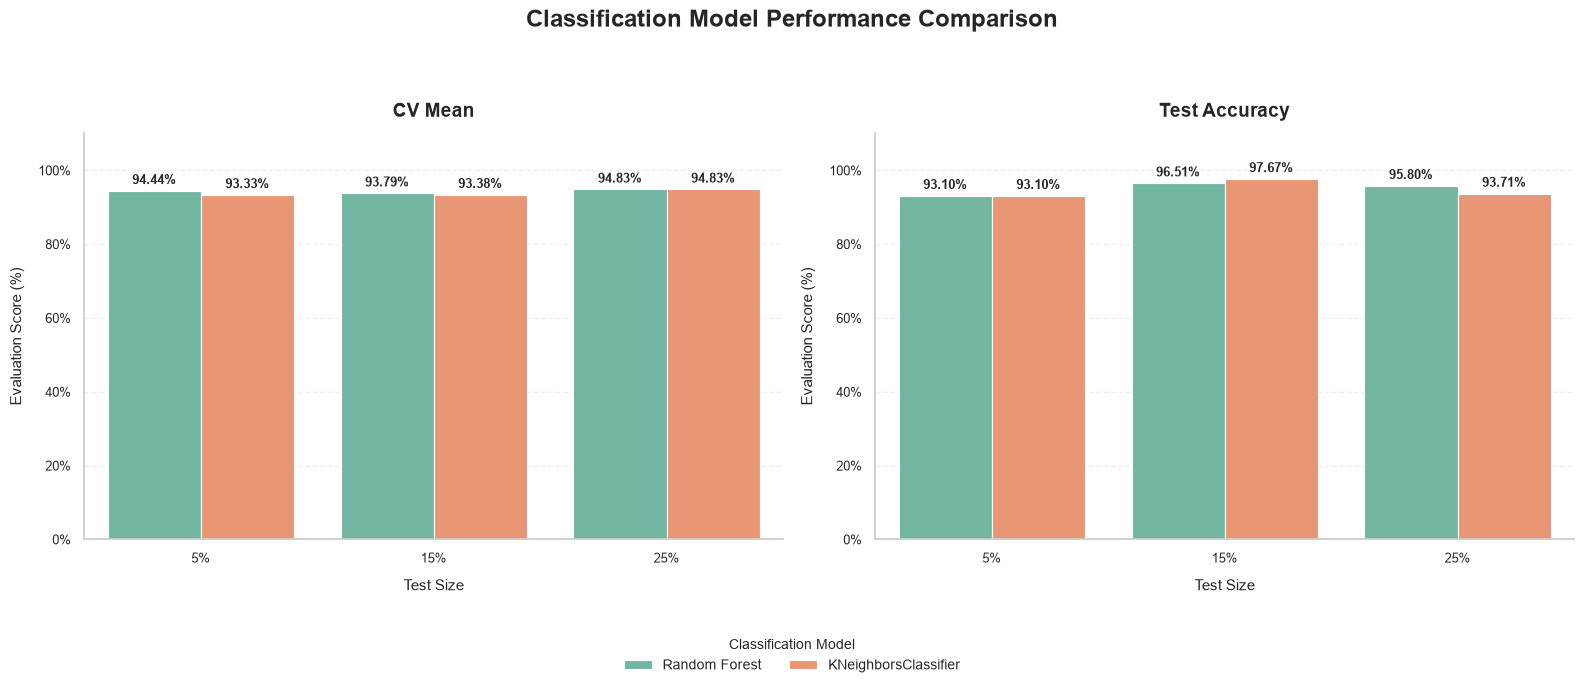

In [60]:
Helpful.F_comparison_plot(data=df_comparison)

### 7️⃣.4️⃣. 📈 Malignant Classification Performance

## 8️⃣. Hyperparameter Tuning (GridSearchCV)

In [61]:
from sklearn.model_selection import GridSearchCV

In [62]:
param_grids = {
    "Random Forest": \
        {
            "n_estimators": [50, 100, 200],
            "max_depth": [None, 5, 10, 20, 30],
        },
    "k-Nearest Neighbors": \
        {
            "n_neighbors": [3, 5, 7, 9, 11],
        },
}

In [63]:
param_grids

{'Random Forest': {'n_estimators': [50, 100, 200],
  'max_depth': [None, 5, 10, 20, 30]},
 'k-Nearest Neighbors': {'n_neighbors': [3, 5, 7, 9, 11]}}

## 9️⃣. Model Evaluation and Comparison

## 🔟. Conclusion

## 🔎 References ....